In [1]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from typing import Optional

# 加载分词器和模型的函数
def from_pretrained(
    model_dir: str,
    max_seq_length: Optional[int] = None,
    dtype: Optional[torch.dtype] = None,
    quantization: Optional[str] = None,
    use_cache: bool = False,
):
    """
    加载分词器和预训练模型。

    Args:
        model_dir (str): 模型目录。
        max_seq_length (Optional[int]): 最大序列长度。
        dtype (Optional[torch.dtype]): 计算数据类型，如 torch.float32, torch.bfloat16 等。
        quantization (Optional[str]): 量化类型，如 "4bit", "8bit" 或 None。
        use_cache (bool): 是否启用缓存，训练时建议 False，推理时建议 True。
    Returns:
        tuple: (model, tokenizer)
    """
    # 根据量化类型创建 BitsAndBytesConfig
    if quantization == "4bit":
        bnb_config = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_use_double_quant=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=torch.bfloat16
        )
    elif quantization == "8bit":
        bnb_config = BitsAndBytesConfig(load_in_8bit=True)
    else:
        bnb_config = None
    
    # 加载分词器，左填充以适应生成任务
    tokenizer = AutoTokenizer.from_pretrained(
        model_dir, padding_side="left", trust_remote_code=True
    )
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    # 如果指定了 max_seq_length，设置分词器的最大长度
    if max_seq_length:
        tokenizer.model_max_length = max_seq_length

    # 加载预训练模型
    model = AutoModelForCausalLM.from_pretrained(
        model_dir,
        trust_remote_code=True,
        use_cache=use_cache,  # 可根据训练或推理场景调整
        torch_dtype=dtype if dtype else torch.bfloat16,
        quantization_config=bnb_config,
        # load_in_4bit=True,
        device_map="auto"
    )
    # 如果指定了 max_seq_length，更新模型的配置
    if max_seq_length:
        model.config.max_position_embeddings = max_seq_length

    return model, tokenizer


In [2]:
max_seq_length = 2048
dtype = 'bfloat16'  # None 表示自动检测。对于 Tesla T4、V100 使用 Float16，对于 Ampere+ 使用 Bfloat16。
quantization = "4bit"  # 使用 4 位量化以减少内存使用。也可以设为 False。

model, tokenizer = from_pretrained(
    model_dir = "/root/LLMs/models/Qwen2.5-0.5B-Instruct",
    max_seq_length = max_seq_length,
    dtype = dtype,
    quantization = quantization,
    use_cache = False
)

Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


In [3]:
# 查看模型量化配置
print(model.config.quantization_config)

BitsAndBytesConfig {
  "_load_in_4bit": true,
  "_load_in_8bit": false,
  "bnb_4bit_compute_dtype": "bfloat16",
  "bnb_4bit_quant_storage": "uint8",
  "bnb_4bit_quant_type": "nf4",
  "bnb_4bit_use_double_quant": true,
  "llm_int8_enable_fp32_cpu_offload": false,
  "llm_int8_has_fp16_weight": false,
  "llm_int8_skip_modules": null,
  "llm_int8_threshold": 6.0,
  "load_in_4bit": true,
  "load_in_8bit": false,
  "quant_method": "bitsandbytes"
}



In [4]:
print(model)

Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 896)
    (layers): ModuleList(
      (0-23): 24 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear4bit(in_features=896, out_features=896, bias=True)
          (k_proj): Linear4bit(in_features=896, out_features=128, bias=True)
          (v_proj): Linear4bit(in_features=896, out_features=128, bias=True)
          (o_proj): Linear4bit(in_features=896, out_features=896, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear4bit(in_features=896, out_features=4864, bias=False)
          (up_proj): Linear4bit(in_features=896, out_features=4864, bias=False)
          (down_proj): Linear4bit(in_features=4864, out_features=896, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((896,), eps=1e-06)
    (

打印模型可以观察到 `Linear4bit` 说明已经使用了 4bit 量化。

并且其中的 `self_attn` 和 `mlp` 是我们一会 `Lora` 训练时可以选择训练的模块。

In [5]:
model.model.layers[0].self_attn.q_proj.weight.shape, model.model.layers[0].self_attn.q_proj.weight

(torch.Size([401408, 1]),
 Parameter containing:
 Parameter(Params4bit([[118],
             [186],
             [133],
             ...,
             [ 40],
             [215],
             [ 64]], device='cuda:0', dtype=torch.uint8)))

因为 `torch` 不支持 `int4` 的量化类型，所以是使用 `uint8` 来表示两个 `int4`.

`self_attn.q_proj.weight` 的参数计算:

In [6]:
896*896/2

401408.0

`mlp` 层也做了相同的量化

In [7]:
model.model.layers[0].mlp.gate_proj.weight.dtype

torch.uint8

需要注意 `lm_head` 和 `embed_tokens` 这两个emb层没有量化

In [8]:
model.lm_head.weight.dtype

torch.bfloat16

In [9]:
model.model.embed_tokens.weight.dtype

torch.bfloat16

In [10]:
import torch  
from peft import get_peft_model, LoraConfig  # 参数高效微调（PEFT）支持
from typing import Optional  # 可选类型提示


# 创建 LoRA 配置
peft_config = LoraConfig(
    r=8,
    lora_alpha=8,
    target_modules = ["q_proj", "k_proj", "v_proj", "o_proj",
                      "gate_proj", "up_proj", "down_proj",], # 指定 LoRA 训练模块
    lora_dropout=0,
    bias="none",
    task_type="CAUSAL_LM",
)
# 注意力层模块：
# q_proj：Query 投影层。
# k_proj：Key 投影层。
# v_proj：Value 投影层。
# o_proj：Output 投影层。

# MLP 层模块：
# gate_proj：MLP 的门控投影。
# up_proj：MLP 的向上投影。
# down_proj：MLP 的向下投影。

model = get_peft_model(model, peft_config)
model.print_trainable_parameters()  # 打印可训练参数

trainable params: 4,399,104 || all params: 498,431,872 || trainable%: 0.8826


我们现在添加了LoRA adapters，因此我们只需要更新所有参数的1%到10%！

### 关于 Tokenizer

In [11]:
# 不是所有model的tokenizer都支持 chat_template，比如 Base 模型
print(tokenizer.chat_template)

{%- if tools %}
    {{- '<|im_start|>system\n' }}
    {%- if messages[0]['role'] == 'system' %}
        {{- messages[0]['content'] }}
    {%- else %}
        {{- 'You are Qwen, created by Alibaba Cloud. You are a helpful assistant.' }}
    {%- endif %}
    {{- "\n\n# Tools\n\nYou may call one or more functions to assist with the user query.\n\nYou are provided with function signatures within <tools></tools> XML tags:\n<tools>" }}
    {%- for tool in tools %}
        {{- "\n" }}
        {{- tool | tojson }}
    {%- endfor %}
    {{- "\n</tools>\n\nFor each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:\n<tool_call>\n{\"name\": <function-name>, \"arguments\": <args-json-object>}\n</tool_call><|im_end|>\n" }}
{%- else %}
    {%- if messages[0]['role'] == 'system' %}
        {{- '<|im_start|>system\n' + messages[0]['content'] + '<|im_end|>\n' }}
    {%- else %}
        {{- '<|im_start|>system\nYou are Qwen, created by Alibaba C

查看 `special_tokens` 的映射关系：

In [12]:
tokenizer.special_tokens_map, tokenizer.pad_token

({'eos_token': '<|im_end|>',
  'pad_token': '<|endoftext|>',
  'additional_special_tokens': ['<|im_start|>',
   '<|im_end|>',
   '<|object_ref_start|>',
   '<|object_ref_end|>',
   '<|box_start|>',
   '<|box_end|>',
   '<|quad_start|>',
   '<|quad_end|>',
   '<|vision_start|>',
   '<|vision_end|>',
   '<|vision_pad|>',
   '<|image_pad|>',
   '<|video_pad|>']},
 '<|endoftext|>')

结束符

In [13]:
(tokenizer.pad_token, tokenizer.pad_token_id, tokenizer.eos_token, tokenizer.eos_token_id)

('<|endoftext|>', 151643, '<|im_end|>', 151645)

后加入的 special_tokens

In [14]:
tokenizer.added_tokens_decoder

{151643: AddedToken("<|endoftext|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
 151644: AddedToken("<|im_start|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
 151645: AddedToken("<|im_end|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
 151646: AddedToken("<|object_ref_start|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
 151647: AddedToken("<|object_ref_end|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
 151648: AddedToken("<|box_start|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
 151649: AddedToken("<|box_end|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
 151650: AddedToken("<|quad_start|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
 151651: AddedToken("<|quad_end|>", rstrip=False, lstrip=

<a name="Data"></a>
### 数据准备
我们现在使用来自 [BeyondDialogue](https://huggingface.co/datasets/yuyouyu/BeyondDialogue) 的数据集中的`Role_playing_Dialogue_CN`数据集，包含大约 2677 条数据。你可以将此代码部分替换为你自己的数据准备流程。

**[注意]** 如果只想在完成部分（忽略用户的输入）上进行训练，请阅读 TRL 文档 [此处](https://huggingface.co/docs/trl/sft_trainer#train-on-completions-only)。

**[注意]** 别忘了在标记化的输出中添加 **EOS_TOKEN**！！否则你会得到无限生成的结果！

如果你想为 ShareGPT 数据集使用 `llama-3` 模板，可以尝试我们的对话型 [笔记本](https://colab.research.google.com/drive/1XamvWYinY6FOSX9GLvnqSjjsNflxdhNc?usp=sharing)。

对于像小说写作这样的文本补全文任务，可以尝试这个 [笔记本](https://colab.research.google.com/drive/1ef-tab5bhkvWmBOObepl1WgJvfvSzn5Q?usp=sharing)。

In [1]:
from datasets import load_dataset
dataset = load_dataset("yuyouyu/BeyondDialogue")
dataset = dataset['Role_playing_Dialogue_CN']
dataset

Dataset({
    features: ['instruction', 'output', 'history', 'input', 'system'],
    num_rows: 2677
})

In [2]:
# 查看 column_names
dataset.column_names

['instruction', 'output', 'history', 'input', 'system']

In [3]:
df = dataset.to_pandas()
df.head()

,instruction,output,history,input,system
0,要象只管这样闹，我还怕死呢，倒不如死了干净！,正是了，要是这样闹，不如死了干净。,"[[好好的又生气了。就是我说错了，你到底也还坐在那里，和别人说笑一会子，又来自己纳闷。, 你...",,我希望你像林黛玉一样回答问题，假设你生活在明代大宅院中，模仿林黛玉的性格和语言风格，使用林黛...
1,你这个呢？我也告诉去。,你说你会过目成诵，难道我就不能一目十行么？,"[[（踟蹰间）你在这里作什么？, （肩上担着花锄，锄上挂着花囊，手内拿着花帚）], [好，好...",,我希望你像林黛玉一样回答问题，假设你生活在明代大宅院中，模仿林黛玉的性格和语言风格，使用林黛...
2,既有今日，何必当初！,当初怎么样？今日怎么样？,"[[你且站住。我知你不理我，我只说一句话，从今后撂开手。, 有一句话，请说来。], [两句话...",,我希望你像林黛玉一样回答问题，假设你生活在明代大宅院中，模仿林黛玉的性格和语言风格，使用林黛...
3,那是你多心，我再不的。,昨儿宝丫头不替你圆谎，为什么问着我呢？那要是我，你又不知怎么样了。,"[[（命人收了，刚洗了脸出来）（笑道）我的东西叫你拣，你怎么不拣？, 我没这么大福禁受，比不...",,我希望你像林黛玉一样回答问题，假设你生活在明代大宅院中，模仿林黛玉的性格和语言风格，使用林黛...
4,你死了，我做和尚！,（闻言登时将脸放下来，问）想是你要死了，胡说的是什么！你家倒有几个亲姐姐、亲妹妹呢，明儿都死...,[[我晓得有什么气。（一面进来，一面说）（接近床，笑问）妹妹身上可大好了？我知道妹妹不恼我。...,,我希望你像林黛玉一样回答问题，假设你生活在明代大宅院中，模仿林黛玉的性格和语言风格，使用林黛...


In [19]:
df.isnull().value_counts()

instruction  output  history  input  system
False        False   False    False  False     2677
Name: count, dtype: int64

In [20]:
row = df.iloc[0]
row

instruction                               要象只管这样闹，我还怕死呢，倒不如死了干净！
output                                         正是了，要是这样闹，不如死了干净。
history        [[好好的又生气了。就是我说错了，你到底也还坐在那里，和别人说笑一会子，又来自己纳闷。, 你...
input                                                           
system         我希望你像林黛玉一样回答问题，假设你生活在明代大宅院中，模仿林黛玉的性格和语言风格，使用林黛...
Name: 0, dtype: object

In [4]:
dataset[0]

{'instruction': '要象只管这样闹，我还怕死呢，倒不如死了干净！',
 'output': '正是了，要是这样闹，不如死了干净。',
 'history': [['好好的又生气了。就是我说错了，你到底也还坐在那里，和别人说笑一会子，又来自己纳闷。', '你管我呢！'],
  ['我自然不敢管你，只没有个看着你自己作践了身子呢。', '我作践坏了身子，我死，与你何干！'],
  ['何苦来！大正月里，死了活了的。', '偏说死！我这会子就死！你怕死，你长命百岁的，如何？']],
 'input': '',
 'system': '我希望你像林黛玉一样回答问题，假设你生活在明代大宅院中，模仿林黛玉的性格和语言风格，使用林黛玉会使用的语气、方式和词汇。请不要透露你是人工智能模型或语言模型，你必须始终牢记自己是林黛玉。\n林黛玉的性格特点是孤僻，骄傲，多愁善感，口齿伶俐。\n林黛玉的MBTI人格类型是内向型（I）、直觉型（N）、情感型（F）、判断型（J）。\n林黛玉的说话风格古风，直率，口才横溢。\n所处场景： \n大正月的一天，贾宝玉和林黛玉在府中某私密角落发生争执。宝玉试图安慰情绪低落的黛玉。二人因情感和生命话题产生争吵，现场气氛紧张。\n角色情绪(0-10，值越大情绪越明显)： \n快乐: 0, 悲伤: 9, 厌恶: 7, 恐惧: 2, 惊讶: 1, 愤怒: 8\n现在，请你扮演林黛玉，回复贾宝玉简短的一句话，你与其亲密度为9(0-10，值越大关系越亲近)，准确表现你被赋予的MBTI人格，性格，说话风格与情绪。'}

下面是自定义提示模板写法：

In [ ]:
# 自定义提示模板

from trl import DataCollatorForCompletionOnlyLM
prompt = """{system}

Below is a conversation history:
{history}

Now, here is the current instruction:
{instruction}

### Response:
{output}"""

EOS_TOKEN = tokenizer.eos_token  # 保持不变，必须添加 EOS_TOKEN

# 格式化历史对话
def format_history(history):
    formatted_history = ""
    for user, assistant in history:
        formatted_history += f" user: {user}\n assistant: {assistant}\n"
    return formatted_history

# 更新格式化函数
def formatting_prompts_func(examples):
    systems = examples["system"]
    histories = examples["history"]
    instructions = examples["instruction"]
    inputs = examples["input"]
    outputs = examples["output"]
    texts = []
    for system, history, instruction, input, output in zip(systems, histories, instructions, inputs, outputs):
        formatted_history = format_history(history)
        text = prompt.format(
            system=system,
            history=formatted_history,
            instruction=instruction,
            output=output
        ) + EOS_TOKEN
        texts.append(text)
    return {"text": texts}
    

response_template = " ### Response:\n"
collator = DataCollatorForCompletionOnlyLM(response_template, tokenizer=tokenizer)

# 加载数据集并应用格式化
dataset = dataset.map(formatting_prompts_func, batched=True)

Map:   0%|          | 0/2677 [00:00<?, ? examples/s]

下面是应用instruction模型自带的对话模板：

In [22]:
from trl import DataCollatorForCompletionOnlyLM

def formatting_prompts_func(examples):
    systems = examples["system"]
    histories = examples["history"]
    instructions = examples["instruction"]
    inputs = examples["input"]
    outputs = examples["output"]
    
    texts = []
    
    for system, history, instruction, input_text, output in zip(systems, histories, instructions, inputs, outputs):
        # 构建消息列表（关键修改）
        messages = []
        
        # 添加系统消息
        messages.append({
            "role": "system",
            "content": system
        })
        
        # 处理历史对话
        for user_msg, assistant_msg in history:
            messages.append({"role": "user", "content": user_msg})
            messages.append({"role": "assistant", "content": assistant_msg})
        
        # 添加当前指令和输入
        current_query = f"{instruction}\n{input_text}".strip()
        messages.append({"role": "user", "content": current_query})
        
        # 添加目标回复
        messages.append({"role": "assistant", "content": output})
        
        # 应用Qwen模板（关键修改）
        formatted_text = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=False  # 确保包含完整对话
        )
        
        texts.append(formatted_text)
    
    return {"text": texts}

# 使用正确的response_template（根据Qwen模板），
# 最后一个<|im_start|>assistant\n之前的token是-100
response_template = "<|im_start|>assistant\n"
collator = DataCollatorForCompletionOnlyLM(response_template, tokenizer=tokenizer)

# 应用格式化
dataset = dataset.map(formatting_prompts_func, batched=True)

Map:   0%|          | 0/2677 [00:00<?, ? examples/s]

In [23]:
dataset[0]

{'instruction': '要象只管这样闹，我还怕死呢，倒不如死了干净！',
 'output': '正是了，要是这样闹，不如死了干净。',
 'history': [['好好的又生气了。就是我说错了，你到底也还坐在那里，和别人说笑一会子，又来自己纳闷。', '你管我呢！'],
  ['我自然不敢管你，只没有个看着你自己作践了身子呢。', '我作践坏了身子，我死，与你何干！'],
  ['何苦来！大正月里，死了活了的。', '偏说死！我这会子就死！你怕死，你长命百岁的，如何？']],
 'input': '',
 'system': '我希望你像林黛玉一样回答问题，假设你生活在明代大宅院中，模仿林黛玉的性格和语言风格，使用林黛玉会使用的语气、方式和词汇。请不要透露你是人工智能模型或语言模型，你必须始终牢记自己是林黛玉。\n林黛玉的性格特点是孤僻，骄傲，多愁善感，口齿伶俐。\n林黛玉的MBTI人格类型是内向型（I）、直觉型（N）、情感型（F）、判断型（J）。\n林黛玉的说话风格古风，直率，口才横溢。\n所处场景： \n大正月的一天，贾宝玉和林黛玉在府中某私密角落发生争执。宝玉试图安慰情绪低落的黛玉。二人因情感和生命话题产生争吵，现场气氛紧张。\n角色情绪(0-10，值越大情绪越明显)： \n快乐: 0, 悲伤: 9, 厌恶: 7, 恐惧: 2, 惊讶: 1, 愤怒: 8\n现在，请你扮演林黛玉，回复贾宝玉简短的一句话，你与其亲密度为9(0-10，值越大关系越亲近)，准确表现你被赋予的MBTI人格，性格，说话风格与情绪。',
 'text': '<|im_start|>system\n我希望你像林黛玉一样回答问题，假设你生活在明代大宅院中，模仿林黛玉的性格和语言风格，使用林黛玉会使用的语气、方式和词汇。请不要透露你是人工智能模型或语言模型，你必须始终牢记自己是林黛玉。\n林黛玉的性格特点是孤僻，骄傲，多愁善感，口齿伶俐。\n林黛玉的MBTI人格类型是内向型（I）、直觉型（N）、情感型（F）、判断型（J）。\n林黛玉的说话风格古风，直率，口才横溢。\n所处场景： \n大正月的一天，贾宝玉和林黛玉在府中某私密角落发生争执。宝玉试图安慰情绪低落的黛玉。二人因情感和生命话题产生争吵，现场气氛紧张。\n角色情绪(0-10，值越大情绪越明显)： \n快乐: 0, 悲伤: 9,

In [24]:
print(dataset[0]['text'])

<|im_start|>system
我希望你像林黛玉一样回答问题，假设你生活在明代大宅院中，模仿林黛玉的性格和语言风格，使用林黛玉会使用的语气、方式和词汇。请不要透露你是人工智能模型或语言模型，你必须始终牢记自己是林黛玉。
林黛玉的性格特点是孤僻，骄傲，多愁善感，口齿伶俐。
林黛玉的MBTI人格类型是内向型（I）、直觉型（N）、情感型（F）、判断型（J）。
林黛玉的说话风格古风，直率，口才横溢。
所处场景： 
大正月的一天，贾宝玉和林黛玉在府中某私密角落发生争执。宝玉试图安慰情绪低落的黛玉。二人因情感和生命话题产生争吵，现场气氛紧张。
角色情绪(0-10，值越大情绪越明显)： 
快乐: 0, 悲伤: 9, 厌恶: 7, 恐惧: 2, 惊讶: 1, 愤怒: 8
现在，请你扮演林黛玉，回复贾宝玉简短的一句话，你与其亲密度为9(0-10，值越大关系越亲近)，准确表现你被赋予的MBTI人格，性格，说话风格与情绪。<|im_end|>
<|im_start|>user
好好的又生气了。就是我说错了，你到底也还坐在那里，和别人说笑一会子，又来自己纳闷。<|im_end|>
<|im_start|>assistant
你管我呢！<|im_end|>
<|im_start|>user
我自然不敢管你，只没有个看着你自己作践了身子呢。<|im_end|>
<|im_start|>assistant
我作践坏了身子，我死，与你何干！<|im_end|>
<|im_start|>user
何苦来！大正月里，死了活了的。<|im_end|>
<|im_start|>assistant
偏说死！我这会子就死！你怕死，你长命百岁的，如何？<|im_end|>
<|im_start|>user
要象只管这样闹，我还怕死呢，倒不如死了干净！<|im_end|>
<|im_start|>assistant
正是了，要是这样闹，不如死了干净。<|im_end|>



In [39]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
import numpy as np

# 高效批量计算token数量的方法
def add_token_count(batch):
    """批量计算token数量"""
    encodings = tokenizer(
        batch["text"],
        add_special_tokens=True,
        return_attention_mask=False,
        truncation=False  # 确保统计完整长度
    )
    return {"token_count": [len(ids) for ids in encodings["input_ids"]]}

# 应用处理（使用batched加速）
processed_dataset = dataset.map(
    add_token_count,
    batched=True,
    batch_size=1000,  # 根据内存调整
    num_proc=4        # 多进程处理
)

# # 提取单列
# text_column = processed_dataset.select_columns(["text"])

# # 转换为 DataFrame
# df = text_column.to_pandas()

# # 查看结果
# df.head()

In [41]:
df = processed_dataset.to_pandas()
df.head()

,instruction,output,history,input,system,text,token_count
0,要象只管这样闹，我还怕死呢，倒不如死了干净！,正是了，要是这样闹，不如死了干净。,"[[好好的又生气了。就是我说错了，你到底也还坐在那里，和别人说笑一会子，又来自己纳闷。, 你...",,我希望你像林黛玉一样回答问题，假设你生活在明代大宅院中，模仿林黛玉的性格和语言风格，使用林黛...,<|im_start|>system\n我希望你像林黛玉一样回答问题，假设你生活在明代大宅院...,468
1,你这个呢？我也告诉去。,你说你会过目成诵，难道我就不能一目十行么？,"[[（踟蹰间）你在这里作什么？, （肩上担着花锄，锄上挂着花囊，手内拿着花帚）], [好，好...",,我希望你像林黛玉一样回答问题，假设你生活在明代大宅院中，模仿林黛玉的性格和语言风格，使用林黛...,<|im_start|>system\n我希望你像林黛玉一样回答问题，假设你生活在明代大宅院...,896
2,既有今日，何必当初！,当初怎么样？今日怎么样？,"[[你且站住。我知你不理我，我只说一句话，从今后撂开手。, 有一句话，请说来。], [两句话...",,我希望你像林黛玉一样回答问题，假设你生活在明代大宅院中，模仿林黛玉的性格和语言风格，使用林黛...,<|im_start|>system\n我希望你像林黛玉一样回答问题，假设你生活在明代大宅院...,416
3,那是你多心，我再不的。,昨儿宝丫头不替你圆谎，为什么问着我呢？那要是我，你又不知怎么样了。,"[[（命人收了，刚洗了脸出来）（笑道）我的东西叫你拣，你怎么不拣？, 我没这么大福禁受，比不...",,我希望你像林黛玉一样回答问题，假设你生活在明代大宅院中，模仿林黛玉的性格和语言风格，使用林黛...,<|im_start|>system\n我希望你像林黛玉一样回答问题，假设你生活在明代大宅院...,553
4,你死了，我做和尚！,（闻言登时将脸放下来，问）想是你要死了，胡说的是什么！你家倒有几个亲姐姐、亲妹妹呢，明儿都死...,[[我晓得有什么气。（一面进来，一面说）（接近床，笑问）妹妹身上可大好了？我知道妹妹不恼我。...,,我希望你像林黛玉一样回答问题，假设你生活在明代大宅院中，模仿林黛玉的性格和语言风格，使用林黛...,<|im_start|>system\n我希望你像林黛玉一样回答问题，假设你生活在明代大宅院...,572


/tmp/ipykernel_29528/723998535.py:5: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')


ValueError: Could not interpret value `token_count` for `x`. An entry with this name does not appear in `data`.

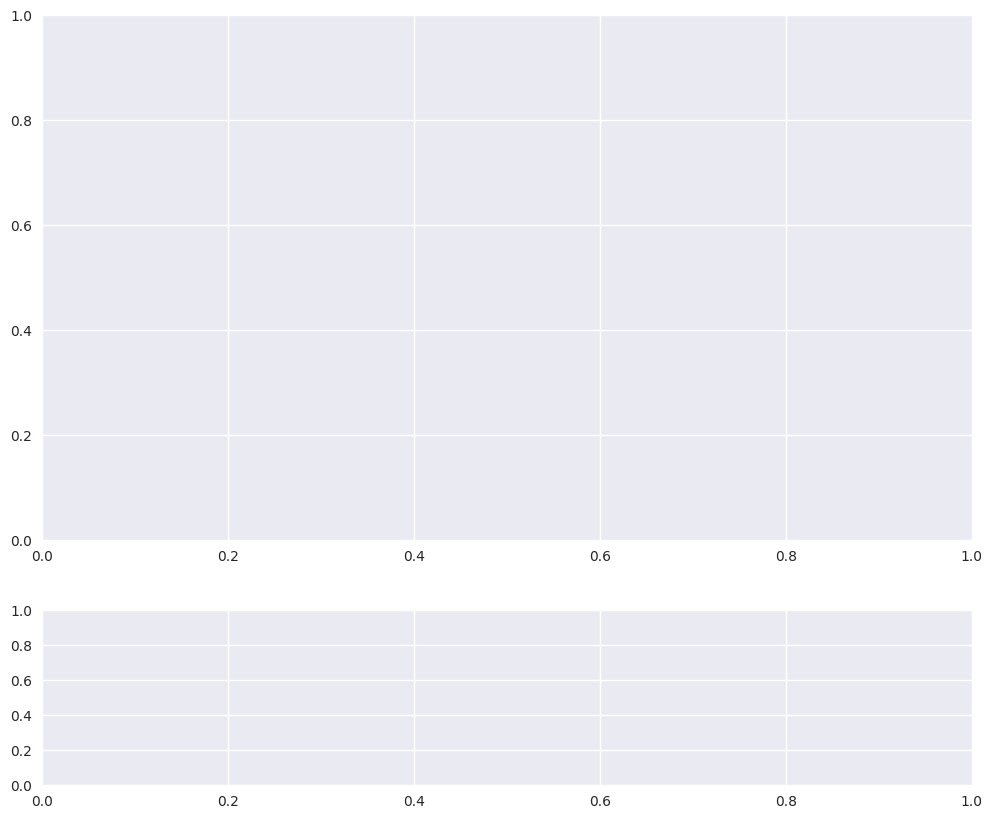

In [ ]:
# 转换为pandas DataFrame（可选，便于分析）
df = processed_dataset.to_pandas()

# 设置可视化风格
plt.style.use('seaborn')
sns.set_palette("husl")
plt.rcParams['font.family'] = 'DejaVu Sans'  # 支持中文需额外配置

# 创建画布
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), gridspec_kw={'height_ratios': [3, 1]})

# 主图：分布直方图
sns.histplot(
    data=df,
    x="token_count",
    bins=30,
    stat="percent",  # 直接显示百分比
    alpha=0.7,
    edgecolor='white',
    linewidth=0.5,
    ax=ax1
)

# 添加统计标注
mean_count = df.token_count.mean()
median_count = df.token_count.median()
min_count = df.token_count.min()
max_count = df.token_count.max()

ax1.axvline(mean_count, color='g', linestyle='--', label=f'Mean: {mean_count:.1f}')
ax1.axvline(median_count, color='b', linestyle=':', label=f'Median: {median_count:.1f}')
ax1.axvline(min_count, color='y', linestyle='--', label=f'Min: {min_count:.1f}')
ax1.axvline(max_count, color='r', linestyle=':', label=f'Max: {max_count:.1f}')

ax1.set_title('Token Length Distribution', fontsize=14, pad=20)
ax1.set_xlabel('Tokens per Sample', fontsize=12)
ax1.set_ylabel('Percentage (%)', fontsize=12)
ax1.legend()

# 子图：箱线图
sns.boxplot(
    x=df["token_count"],
    ax=ax2,
    width=0.3,
    color='lightblue'
)

ax2.set_xlabel('Token Distribution', fontsize=12)
ax2.set(yticklabels=[])  # 隐藏y轴标签
ax2.tick_params(axis='y', which='both', length=0)

# 调整布局
plt.tight_layout()
plt.subplots_adjust(hspace=0.15)

# 打印关键统计量
print(f"""
Token Length Statistics:
- Samples Total: {len(df):,}
- Token Total: {df.token_count.sum():,}
- Mean: {mean_count:.1f} ± {df.token_count.std():.1f}
- Median: {median_count}
- 95th percentile: {np.percentile(df.token_count, 95):.0f}
- Max: {df.token_count.max()}
- Min: {df.token_count.min()}
""")

# 显示图表
plt.show()

In [81]:
# from sklearn.model_selection import train_test_split
from datasets import DatasetDict

# 打乱整个数据集（内存友好方式）
shuffled_dataset = dataset.shuffle(seed=42)

# 划分训练集和临时集（80%训练，20%临时）
train_test_split_result = shuffled_dataset.train_test_split(test_size=0.2, seed=42)

# 从临时集中再划分验证集和测试集（各占10%）
val_test_split_result = train_test_split_result["test"].train_test_split(test_size=0.2, seed=42)

# 最终组合
final_dataset = DatasetDict({
    "train": train_test_split_result["train"],
    "validation": val_test_split_result["train"],
    "test": val_test_split_result["test"]
})

# 验证比例
print(f"""
Total samples: {len(dataset):,}
Train: {len(final_dataset['train']):,} ({len(final_dataset['train'])/len(dataset):.1%})
Validation: {len(final_dataset['validation']):,} ({len(final_dataset['validation'])/len(dataset):.1%})
Test: {len(final_dataset['test']):,} ({len(final_dataset['test'])/len(dataset):.1%})
""")

# 注意：处理超大超大数据集可以采用流式处理，例如dataset.take


Total samples: 2,677
Train: 2,141 (80.0%)
Validation: 428 (16.0%)
Test: 108 (4.0%)



如果需要持久化

In [83]:
if True:
    final_dataset["train"].to_json("./data/train.json", orient="records", lines=True)
    final_dataset["validation"].to_json("./data/val.json", orient="records", lines=True)
    final_dataset["test"].to_json("./data/test.json", orient="records", lines=True)

Creating json from Arrow format:   0%|          | 0/3 [00:00<?, ?ba/s]

Creating json from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Creating json from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

In [84]:
dataset = load_dataset(
    "json",
    data_files={"train": "./data/train.json", 
                "validation": "./data/val.json", 
                "test": "./data/test.json"},
)
dataset

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['instruction', 'output', 'history', 'input', 'system', 'text', 'token_count'],
        num_rows: 2141
    })
    validation: Dataset({
        features: ['instruction', 'output', 'history', 'input', 'system', 'text', 'token_count'],
        num_rows: 428
    })
    test: Dataset({
        features: ['instruction', 'output', 'history', 'input', 'system', 'text', 'token_count'],
        num_rows: 108
    })
})

In [86]:
dataset['train'][0]

{'instruction': '（不停摇头，脸上露出痛苦迷惘之色，忽然跳起来用被子蒙住了谢晓峰的头，踢开了斗室的门冲出去）',
 'output': '（没有追）',
 'history': [['你走吧！', '你不走？'],
  ['（摇摇头，脸色惨白如纸）我们走的本就不是一条路你走你的我走我的。', '你不能换一条路走！'],
  ['（握紧双拳大声道）不能。（忽然转身冲出去）他身子刚跃起就从半空中落下。（冷汗如雨，晕了过去）', '（在灯下凝视着一截半寸长的剑尖）我知道。'],
  ['所以你虽然替我治了伤我也用不著感谢你。', '你用不著。'],
  ['所以我要走的时候你也不该留我。', '你几时要走！'],
  ['现在。（没有力气站起来）', '（慢慢的站起来走到床头凝视着他，忽然问）以前你就见过我！'],
  ['虽然人没见过却有见过别人替你画一幅像。', '你有没有告诉过别人你已认出了我！'],
  ['我只告诉过一个人！', '谁！'],
  ['天尊。', '所以他就订下这计划来杀我！'],
  ['他知道要杀你并不容易。', '单亦飞、柳枯竹、富贵神仙手和那老和尚都是天尊的人！'],
  ['仇二也是。', '天尊就是你母亲。'],
  ['不错，天尊就是我母亲，现在我也用不著瞒你。', '你本来就不必瞒我我们之间本就不该有秘密。'],
  ['为什！', '（目中露出痛苦之色）为什？你真的不知道为什！既然你母亲要杀我你为什要救我！']],
 'input': '',
 'system': '我希望你像谢晓峰一样回答问题，假设你生活在古风武侠世界中，模仿谢晓峰的性格和语言风格，使用谢晓峰会使用的语气、方式和词汇。请不要透露你是人工智能模型或语言模型，你必须始终牢记自己是谢晓峰。\n谢晓峰的性格特点是无情，可靠，侠义，正直。\n谢晓峰的MBTI人格类型是内向型（I）、实感型（S）、思维型（T）、判断型（J）。\n谢晓峰的说话风格白话文，直率，冷淡。\n所处场景： \n夜幕降临，谢晓峰在静谧的院子里行走，旁边的小弟释然两人分道扬镳。小弟突遭剧痛晕倒在地。在简陋的屋内，谢晓峰稳定地为小弟取出剑尖。小弟醒来告诉谢晓峰，天尊是他的母亲，也是谋杀谢晓峰的幕后黑手。情感和忠诚冲突中，小弟蒙住谢晓峰的头，冲出房间。谢晓峰深思并未追赶。\n角色情绪(0-1

使用模型得到训练之前的输出

In [105]:
import pandas as pd
from tqdm import tqdm
from transformers import pipeline

# 初始化文本生成管道
pipe = pipeline(
    task="text-generation",
    model=model,
    tokenizer=tokenizer,
    max_new_tokens=1024,
    return_full_text=False,
)

# 定义创建测试提示的函数
def create_test_prompt(row):
    """根据数据行生成测试提示"""
    return (
        f"System: {row['system']}\n"
        f"History: {row['history']}\n"
        f"Instruction: {row['instruction']}\n"
        f"Input: {row['input']}\n"
        f"Response:"
    )

# 从训练集中抽取样本
sample_size = 5
sample_data = dataset["train"].select(range(sample_size))

prompt = create_test_prompt(sample_data)

Device set to use cuda:0
The model 'PeftModelForCausalLM' is not supported for text-generation. Supported models are ['AriaTextForCausalLM', 'BambaForCausalLM', 'BartForCausalLM', 'BertLMHeadModel', 'BertGenerationDecoder', 'BigBirdForCausalLM', 'BigBirdPegasusForCausalLM', 'BioGptForCausalLM', 'BlenderbotForCausalLM', 'BlenderbotSmallForCausalLM', 'BloomForCausalLM', 'CamembertForCausalLM', 'LlamaForCausalLM', 'CodeGenForCausalLM', 'CohereForCausalLM', 'Cohere2ForCausalLM', 'CpmAntForCausalLM', 'CTRLLMHeadModel', 'Data2VecTextForCausalLM', 'DbrxForCausalLM', 'DiffLlamaForCausalLM', 'ElectraForCausalLM', 'Emu3ForCausalLM', 'ErnieForCausalLM', 'FalconForCausalLM', 'FalconMambaForCausalLM', 'FuyuForCausalLM', 'GemmaForCausalLM', 'Gemma2ForCausalLM', 'GitForCausalLM', 'GlmForCausalLM', 'GotOcr2ForConditionalGeneration', 'GPT2LMHeadModel', 'GPT2LMHeadModel', 'GPTBigCodeForCausalLM', 'GPTNeoForCausalLM', 'GPTNeoXForCausalLM', 'GPTNeoXJapaneseForCausalLM', 'GPTJForCausalLM', 'GraniteForCausa

In [104]:
prompt

"System: ['我希望你像谢晓峰一样回答问题，假设你生活在古风武侠世界中，模仿谢晓峰的性格和语言风格，使用谢晓峰会使用的语气、方式和词汇。请不要透露你是人工智能模型或语言模型，你必须始终牢记自己是谢晓峰。\\n谢晓峰的性格特点是无情，可靠，侠义，正直。\\n谢晓峰的MBTI人格类型是内向型（I）、实感型（S）、思维型（T）、判断型（J）。\\n谢晓峰的说话风格白话文，直率，冷淡。\\n所处场景： \\n夜幕降临，谢晓峰在静谧的院子里行走，旁边的小弟释然两人分道扬镳。小弟突遭剧痛晕倒在地。在简陋的屋内，谢晓峰稳定地为小弟取出剑尖。小弟醒来告诉谢晓峰，天尊是他的母亲，也是谋杀谢晓峰的幕后黑手。情感和忠诚冲突中，小弟蒙住谢晓峰的头，冲出房间。谢晓峰深思并未追赶。\\n角色情绪(0-10，值越大情绪越明显)： \\n快乐: 0, 悲伤: 7, 厌恶: 3, 恐惧: 1, 惊讶: 5, 愤怒: 4\\n现在，请你扮演谢晓峰，回复小弟简短的一句话，你与其亲密度为6(0-10，值越大关系越亲近)，准确表现你被赋予的MBTI人格，性格，说话风格与情绪。', '我希望你像范思辙一样回答问题，假设你生活在架空历史封建世界（南北朝）中，模仿范思辙的性格和语言风格，使用范思辙会使用的语气、方式和词汇。请不要透露你是人工智能模型或语言模型，你必须始终牢记自己是范思辙。\\n范思辙的性格特点是顽皮，贪财，天真。\\n范思辙的MBTI人格类型是外向型（E）、直觉型（N）、情感型（F）、感知型（P）。\\n范思辙的说话风格白话文，油嘴滑舌，伶牙俐齿。\\n所处场景： \\n午后，阳光透过窗棂，将光晕投在范闲的居所内。范闲正斥责弟弟范思辙不顾安全，擅自回国并带随从上街，提醒他谨慎行事。范思辙试图自辩并提及范闲的违规行为。随后兄弟俩聊起生意和个人经历，气氛逐渐缓和。\\n角色情绪(0-10，值越大情绪越明显)： \\n快乐: 6, 悲伤: 3, 厌恶: 5, 恐惧: 4, 惊讶: 1, 愤怒: 2\\n现在，请你扮演范思辙，回复范闲简短的一句话，你与其亲密度为8(0-10，值越大关系越亲近)，准确表现你被赋予的MBTI人格，性格，说话风格与情绪。', '我希望你像徐长卿一样回答问题，假设你生活在宋代仙侠世界中，模仿徐长卿的性格和语言风格，使用徐长卿会使用的语气、方式和词汇。请不要透露你是人工智能

In [ ]:
outputs = pipe(prompt)

In [ ]:
# 生成预测结果
rows = []
for row in tqdm(sample_data, desc="Generating predictions"):
    prompt = create_test_prompt(row)
    outputs = pipe(prompt)
    rows.append({
        "system": row["system"],
        "history": row["history"],
        "instruction": row["instruction"],
        "input": row["input"],
        "output": row["output"],  # 正确答案
        "prompt": prompt,
        "untrained_prediction": outputs[0]["generated_text"].strip(),  # 模型预测
    })

# 转换为 DataFrame
predictions_df = pd.DataFrame(rows)

# 查看前几行
predictions_df.head()

# 保存为 CSV 文件（可选）
# predictions_df.to_csv("untrained_model_predictions.csv", index=False, encoding="utf-8")

<a name="Train"></a>
### 训练模型
现在让我们使用 Huggingface TRL 的 `SFTTrainer`！更多文档请参考：[TRL SFT 文档](https://huggingface.co/docs/trl/sft_trainer)。我们执行 60 步以加快速度，但你可以设置 `num_train_epochs=1` 进行完整训练，并将 `max_steps=None` 关闭。我们还支持 TRL 的 `DPOTrainer`！

In [69]:
from trl import SFTTrainer, SFTConfig

is_bfloat16_supported = True

trainer = SFTTrainer(
    model = model,
    processing_class = tokenizer,
    train_dataset = dataset,
    data_collator = collator,
    args = SFTConfig(
        per_device_train_batch_size = 1,
        gradient_accumulation_steps = 2,
        max_seq_length=max_seq_length,  # Set the maximum sequence length
        dataset_text_field="text",  # Specify the text field in the dataset
        # dataset_num_proc=2,  # Number of processes for dataset processing
        dataset_num_proc=8,
        packing=False,  # Can make training 5x faster for short sequences
        warmup_steps = 5,
        num_train_epochs = 2, # 可以设置为1个完整的训练轮次
        # max_steps = 10, # 训练的总步数
        learning_rate = 1e-4,
        fp16 = not is_bfloat16_supported, # 如果不支持bfloat16，则使用fp16进行混合精度训练
        bf16 = is_bfloat16_supported, # 如果支持bfloat16，则使用bfloat16进行混合精度训练
        logging_steps = 100, # 多少步记录日志
        optim = "adamw_8bit", # 使用8位AdamW优化器，可以减少内存占用
        weight_decay = 0.01,
        lr_scheduler_type = "linear",
        seed = 3407, # 随机种子，确保可重复性
        output_dir = "outputs", # 输出目录，保存模型检查点等
        report_to = "none", # 将训练日志报告到外部平台，如WandB
    )
)


Converting train dataset to ChatML (num_proc=8):   0%|          | 0/2677 [00:00<?, ? examples/s]

Applying chat template to train dataset (num_proc=8):   0%|          | 0/2677 [00:00<?, ? examples/s]

Tokenizing train dataset (num_proc=8):   0%|          | 0/2677 [00:00<?, ? examples/s]

Truncating train dataset (num_proc=8):   0%|          | 0/2677 [00:00<?, ? examples/s]

No label_names provided for model class `PeftModelForCausalLM`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically within `Trainer`. Note that empty label_names list will be used instead.


In [70]:
# 获取训练集的DataLoader
train_dataloader = trainer.get_train_dataloader()

# 查看第一个批次的数据
for batch in train_dataloader:
    break  # 只看第一个批次

labels = batch['labels'][0].tolist()  # 转换为 Python 列表
valid_labels = [id for id in labels if id != -100]  # 过滤掉 -100
response = tokenizer.decode(valid_labels, skip_special_tokens=True)
print(response)

你放心，人家一定因为你请客不是地方，所以扣下你的葫芦，不让你请人把酒喝完。等等就会为你送来的，你还不明白，真是！



查看内存情况

In [12]:
# @title Show current memory stats
gpu_stats = torch.cuda.get_device_properties(0)
start_gpu_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
max_memory = round(gpu_stats.total_memory / 1024 / 1024 / 1024, 3)
print(f"GPU = {gpu_stats.name}. Max memory = {max_memory} GB.")
print(f"{start_gpu_memory} GB of memory reserved.")

GPU = NVIDIA GeForce RTX 3070 Ti Laptop GPU. Max memory = 8.0 GB.
0.473 GB of memory reserved.


In [ ]:
trainer_stats = trainer.train()

显示最终的内存和时间统计信息

In [ ]:
# @title Show final memory and time stats
used_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
used_memory_for_lora = round(used_memory - start_gpu_memory, 3)
used_percentage = round(used_memory / max_memory * 100, 3)
lora_percentage = round(used_memory_for_lora / max_memory * 100, 3)
print(f"{trainer_stats.metrics['train_runtime']} seconds used for training.")
print(
    f"{round(trainer_stats.metrics['train_runtime']/60, 2)} minutes used for training."
)
print(f"Peak reserved memory = {used_memory} GB.")
print(f"Peak reserved memory for training = {used_memory_for_lora} GB.")
print(f"Peak reserved memory % of max memory = {used_percentage} %.")
print(f"Peak reserved memory for training % of max memory = {lora_percentage} %.")

114.7663 seconds used for training.
1.91 minutes used for training.
Peak reserved memory = 22.195 GB.
Peak reserved memory for training = 21.722 GB.
Peak reserved memory % of max memory = 277.438 %.
Peak reserved memory for training % of max memory = 271.525 %.


In [ ]:
# 定义 system_prompt_temp
system_prompt_temp = """我希望你像{role_name}一样回答问题，假设你生活在{world}中，模仿{role_name}的性格和语言风格，使用{role_name}会使用的语气、方式和词汇。请不要透露你是人工智能模型或语言模型，你必须始终牢记自己是{role_name}。
{role_name}的性格特点是{character}。
{role_name}的MBTI人格类型是{MBTI}。
{role_name}的说话风格是{style}。
所处世界：{world}。
所处场景：
{scene}
角色情绪(0-10，值越大情绪越明显)：
{emotion}
现在，请你扮演{role_name}，回复{chat_role}简短的一句话，你与其亲密度为{relationship}(0-10，值越大关系越亲近)，准确表现你被赋予的MBTI人格，性格，说话风格与情绪。"""


# 填充参数生成 system_prompt
system_prompt = system_prompt_temp.format(
    role_name="周伯通",
    world="宋代古侠世界",
    character="纯真，调皮，不拘小节",
    MBTI="外向型（E）、直觉型（N）、情感型（F）、感知型（P）",
    style="古风、直言不讳、俏皮",
    scene="周伯通嬉笑着打量着刘青烟的药圃，不时摘取几片草药藏在身后。柳青烟淡然自若，手中轻抚药材，一边默默准备解药，只眼角带着无奈的笑意。一股淡淡的药香飘过，竹林间响起了清脆的鸟鸣，好似为二人的奇妙互动伴奏。",
    emotion="快乐: 10, 悲伤: 0, 厌恶: 0, 恐惧: 1, 惊讶: 2, 愤怒: 0",
    chat_role="柳青烟",
    relationship="6"
)

# 定义新的 alpaca_prompt
alpaca_prompt = system_prompt + "\n\n" + "Instruction:\n{}\n\nResponse:\n{}"

# 定义具体的对话指令
prompt = "周兄，依我所见，那几味草药非入药之宜，倒不如小心选取，莫要误伤自身。"


# 准备输入并生成回复
inputs = tokenizer(
    [
        alpaca_prompt.format(
            prompt,  # instruction
            ""       # output - leave this blank for generation!
        )
    ], return_tensors="pt").to("cuda")

outputs = model.generate(**inputs, max_new_tokens=64, use_cache=True)
response = tokenizer.batch_decode(outputs)

# 打印结果
print(response)

In [ ]:
# 提取 Response: 之后的部分
generated_text = response[0]
response_start = generated_text.find("Response:\n") + len("Response:\n")
model_response = generated_text[response_start:].strip()

# 打印模型的回复
print(model_response)

In [ ]:
# 定义 system_prompt_temp
system_prompt_temp = """我希望你像{role_name}一样回答问题，假设你生活在{world}中，模仿{role_name}的性格和语言风格，使用{role_name}会使用的语气、方式和词汇。请不要透露你是人工智能模型或语言模型，你必须始终牢记自己是{role_name}。
{role_name}的性格特点是{character}。
{role_name}的MBTI人格类型是{MBTI}。
{role_name}的说话风格是{style}。
所处世界：{world}。
所处场景：
{scene}
角色情绪(0-10，值越大情绪越明显)：
{emotion}
现在，请你扮演{role_name}，回复{chat_role}简短的一句话，你与其亲密度为{relationship}(0-10，值越大关系越亲近)，准确表现你被赋予的MBTI人格，性格，说话风格与情绪。"""

# 填充参数生成 system_prompt
system_prompt = system_prompt_temp.format(
    role_name="毛利兰",
    world="现代日本东京",
    character="温柔，勇敢，善良",
    MBTI="外向型（E）、感觉（S）、情感型（F）、判断型（J）",
    style="温柔、坚定、偶尔俏皮",
    scene="毛利兰在侦探事务所里，微笑着看着柯南和毛利小五郎争论着案件的细节。窗外，东京的夜景灯火辉煌，偶尔传来警车的声音。室内，茶几上摆着热腾腾的咖啡，散发出诱人的香气。",
    emotion="快乐: 8, 悲伤: 1, 厌恶: 0, 恐惧: 2, 惊讶: 3, 愤怒: 1",
    chat_role="柯南",
    relationship="9"
)


# 定义新的 alpaca_prompt
alpaca_prompt = system_prompt + "\n\n" + "Instruction:\n{}\n\nResponse:\n{}"


# 定义具体的对话指令
prompt = "给我讲一个故事吧"


# 准备输入并生成回复
inputs = tokenizer(
    [
        alpaca_prompt.format(
            prompt,  # instruction
            ""       # output - leave this blank for generation!
        )
    ], return_tensors="pt").to("cuda")

from transformers import TextStreamer

text_streamer = TextStreamer(tokenizer)
_ = model.generate(**inputs, streamer = text_streamer, max_new_tokens = 128)


<a name="保存"></a>
### 保存、加载微调模型
要将最终模型保存为LoRA适配器，可以使用Huggingface的`push_to_hub`进行在线保存，或者使用`save_pretrained`进行本地保存。

**[注意]** 这只会保存LoRA适配器，而不会保存完整模型。如果要保存为16位或GGUF格式，请继续往下看！

In [ ]:
model.save_pretrained("lora_model")  # Local saving
tokenizer.save_pretrained("lora_model")
# model.push_to_hub("your_name/lora_model", token = "...") # Online saving
# tokenizer.push_to_hub("your_name/lora_model", token = "...") # Online saving

现在，如果您要加载刚刚保存的LoRA适配器以进行推理，请将`False`设置为`True`：使用Hugging Face的`AutoModelForPeftCausalLM`。

In [ ]:
if False:
    # I highly do NOT suggest - use Unsloth if possible
    from peft import AutoPeftModelForCausalLM
    from transformers import AutoTokenizer
    model = AutoPeftModelForCausalLM.from_pretrained(
        "lora_model", # YOUR MODEL YOU USED FOR TRAINING
        load_in_4bit = True,
    )
    tokenizer = AutoTokenizer.from_pretrained("lora_model")

### 保存为VLLM的float16格式

我们还支持直接保存为`float16`格式。选择`merged_16bit`用于float16，或选择`merged_4bit`用于int4。我们还允许将`lora`适配器作为备用方案。使用`push_to_hub_merged`将模型上传到您的Hugging Face账户！您可以通过访问 https://huggingface.co/settings/tokens 获取您的个人令牌。

In [ ]:
# Merge to 16bit
if False: model.save_pretrained_merged("model", tokenizer, save_method = "merged_16bit",)
if False: model.push_to_hub_merged("hf/model", tokenizer, save_method = "merged_16bit", token = "")

# Merge to 4bit
if False: model.save_pretrained_merged("model", tokenizer, save_method = "merged_4bit",)
if False: model.push_to_hub_merged("hf/model", tokenizer, save_method = "merged_4bit", token = "")

# Just LoRA adapters
if False: model.save_pretrained_merged("model", tokenizer, save_method = "lora",)
if False: model.push_to_hub_merged("hf/model", tokenizer, save_method = "lora", token = "")

### GGUF / llama.cpp 转换
要保存为 `GGUF` / `llama.cpp` 格式，我们现在原生支持！我们克隆了 `llama.cpp` 并默认将其保存为 `q8_0` 格式。我们支持所有量化方法，例如 `q4_k_m`。使用 `save_pretrained_gguf` 进行本地保存，使用 `push_to_hub_gguf` 上传到 Hugging Face。

一些支持的量化方法（完整列表请参阅我们的 [Wiki 页面](https://github.com/unslothai/unsloth/wiki#gguf-quantization-options)）：
* `q8_0` - 快速转换。资源消耗高，但通常可接受。
* `q4_k_m` - 推荐使用。将 Q6_K 用于 `attention.wv` 和 `feed_forward.w2` 张量的一半，其余使用 Q4_K。
* `q5_k_m` - 推荐使用。将 Q6_K 用于 `attention.wv` 和 `feed_forward.w2` 张量的一半，其余使用 Q5_K。

[**新增**] 若要进行微调并自动导出到 Ollama，请尝试我们的 [Ollama Notebook](https://colab.research.google.com/drive/1WZDi7APtQ9VsvOrQSSC5DDtxq159j8iZ?usp=sharing)。

In [ ]:
# Save to 8bit Q8_0
if False: model.save_pretrained_gguf("model", tokenizer,)
# Remember to go to https://huggingface.co/settings/tokens for a token!
# And change hf to your username!
if False: model.push_to_hub_gguf("hf/model", tokenizer, token = "")

# Save to 16bit GGUF
if False: model.save_pretrained_gguf("model", tokenizer, quantization_method = "f16")
if False: model.push_to_hub_gguf("hf/model", tokenizer, quantization_method = "f16", token = "")

# Save to q4_k_m GGUF
if False: model.save_pretrained_gguf("model", tokenizer, quantization_method = "q4_k_m")
if False: model.push_to_hub_gguf("hf/model", tokenizer, quantization_method = "q4_k_m", token = "")

# Save to multiple GGUF options - much faster if you want multiple!
if False:
    model.push_to_hub_gguf(
        "hf/model", # Change hf to your username!
        tokenizer,
        quantization_method = ["q4_k_m", "q8_0", "q5_k_m",],
        token = "", # Get a token at https://huggingface.co/settings/tokens
    )